# MATH482 – Wind Power Mean Prediction
**Final model:** spatial neural network over all seven farms + learned per-farm cross-farm weather imputation (Exp02-rescaled), 3-seed average.

Contents
1. Setup & shared code
2. EDA (missing weather blocks, cross-farm correlation, wind→power, train vs test)
3. Chronological validation protocol
4. Experiment log (Exp00 → Exp02), paired comparisons
5. Final model: executed 4-fold chronological CV (overall validation RMSE)
6. Final training on all training data → test predictions → `final_submission.csv`
7. Conclusions & limitations

**Rules compliance.** Folds are split on `issue_time` (expanding window). Every learned step (imputers, medians, standardisation) is fit on the fold's training part only. Features only combine forecasts with the *same* `issue_time`. `power` is never an input feature. The final predictor is a neural network.

## 1. Setup & shared code
The two helper modules used by all experiment scripts are embedded here so the notebook runs on its own (it needs only `train.csv`, `test.csv`, `sample_submission.csv`).

In [3]:
import os, time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from torch import nn
T0 = time.time()

In [4]:
# ---- cv_utils.py ----
"""
cv_utils.py  -  shared chronological validation for MATH482 wind power.

Rules enforced here:
  * folds are split on issue_time (a whole 24h forecast stays in one side)
  * anything learned (medians, scalers, imputers) is fit on the fold's train part only
  * features may only combine rows that share the same issue_time
  * power is never used as an input feature
"""
import os
import random
import numpy as np
import pandas as pd

WEATHER = ["u", "v", "ws"]
FARMS = [1, 2, 3, 4, 5, 6, 7]

# Expanding-window folds. F1 (Apr-Jun 2011) is the same season as the test set.
FOLDS = [
    ("F1_2011Q2", "2011-04-01", "2011-07-01"),
    ("F2_2011Q3", "2011-07-01", "2011-10-01"),
    ("F3_2011Q4", "2011-10-01", "2012-01-01"),
    ("F4_2012Q1", "2012-01-01", "2012-04-01"),
]


def seed_everything(seed):
    import torch
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def load_data(path="."):
    tr = pd.read_csv(os.path.join(path, "train.csv"), parse_dates=["issue_time", "target_time"])
    te = pd.read_csv(os.path.join(path, "test.csv"), parse_dates=["issue_time", "target_time"])
    sample = pd.read_csv(os.path.join(path, "sample_submission.csv"))
    return tr, te, sample


def iter_folds(train):
    for name, start, end in FOLDS:
        trn = train[train.issue_time < start].copy()
        val = train[(train.issue_time >= start) & (train.issue_time < end)].copy()
        # sanity: no issue_time on both sides, no target overlap
        assert trn.issue_time.max() < val.issue_time.min()
        assert trn.target_time.max() < val.target_time.min()
        yield name, trn, val


def rmse(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return float(np.sqrt(np.mean((y - p) ** 2)))


def summarize(oof, label="model"):
    """oof: DataFrame with fold, power, pred, weather_available, farm."""
    rows = []
    for f, d in oof.groupby("fold"):
        rows.append({
            "fold": f,
            "rmse": rmse(d.power, d.pred),
            "rmse_wx_present": rmse(d.power[d.weather_available == 1], d.pred[d.weather_available == 1]),
            "rmse_wx_missing": rmse(d.power[d.weather_available == 0], d.pred[d.weather_available == 0]),
            "n": len(d),
        })
    s = pd.DataFrame(rows).set_index("fold")
    print(f"\n===== {label} =====")
    print(s.round(5))
    print(f"mean fold RMSE   : {s.rmse.mean():.5f}  (std {s.rmse.std():.5f})")
    print(f"pooled OOF RMSE  : {rmse(oof.power, oof.pred):.5f}")
    print(f"F1 (Apr-Jun) RMSE: {s.loc['F1_2011Q2', 'rmse']:.5f}")
    print("per-farm pooled RMSE:",
          oof.groupby("farm").apply(lambda d: round(rmse(d.power, d.pred), 4)).to_dict())
    return s


def make_submission(test, sample, pred, filename):
    assert len(test) == len(sample) and test["id"].is_unique
    assert set(test["id"]) == set(sample["id"])
    sub = sample[["id"]].merge(pd.DataFrame({"id": test["id"].values, "mu": np.clip(pred, 0, 1)}),
                               on="id", how="left", validate="one_to_one")
    assert sub["mu"].notna().all() and np.isfinite(sub["mu"]).all() and len(sub) == 9408
    for protected in ["nn_crossfarm.csv"]:
        assert filename != protected, "do not overwrite the protected submission"
    sub.to_csv(filename, index=False)
    print(f"saved {filename}  rows={len(sub)}  mu mean={sub.mu.mean():.4f}")
    return sub

In [5]:
# ---- wp_lib.py ----
"""
wp_lib.py  -  reusable pieces for experiments >= 01b.
Copies (not imports) the logic of exp00/exp01 so those scripts stay untouched.
Imputed fold data are cached in cache/ so each fold's imputer is trained once.
"""
import os
import pickle
import numpy as np
import pandas as pd
import torch
from torch import nn

# (cv_utils names defined in the cell above)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
KEY = ["issue_time", "target_time"]
NUMERIC = ["u", "v", "ws", "weather_available", "horizon", "ws_squared", "ws_cubed",
           "hour_sin", "hour_cos", "month_sin", "month_cos", "direction_sin", "direction_cos"]
IMP_SEED, IMP_EPOCHS, IMP_HIDE_P = 42, 30, 0.35      # identical to exp01


# ---------------------------------------------------------------- features
def base_features(d):
    d = d.copy()
    d["horizon"] = (d.target_time - d.issue_time).dt.total_seconds() / 3600
    d["hour"] = d.target_time.dt.hour
    d["month"] = d.target_time.dt.month
    d["weather_available"] = d[WEATHER].notna().all(axis=1).astype(int)
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * d.hour / 24), np.cos(2 * np.pi * d.hour / 24)
    d["month_sin"] = np.sin(2 * np.pi * (d.month - 1) / 12)
    d["month_cos"] = np.cos(2 * np.pi * (d.month - 1) / 12)
    return d


def derived(d):
    d = d.copy()
    d["ws_squared"], d["ws_cubed"] = d.ws ** 2, d.ws ** 3
    ang = np.arctan2(d.v, d.u)
    d["direction_sin"], d["direction_cos"] = np.sin(ang), np.cos(ang)
    return d


# ---------------------------------------------------------------- exp00 imputation
def crossfarm_mean_impute(fit_df, d):
    d = d.copy()
    g_med = fit_df[WEATHER].median()
    f_med = fit_df.groupby("farm")[WEATHER].median()
    fm_med = fit_df.groupby(["farm", "month"])[WEATHER].median()
    for c in WEATHER:
        cf = d.groupby(KEY)[c].transform("mean")
        fm = pd.Series(pd.MultiIndex.from_frame(d[["farm", "month"]]).map(fm_med[c]), index=d.index)
        d[c] = d[c].fillna(cf).fillna(fm).fillna(d.farm.map(f_med[c])).fillna(g_med[c])
    return derived(d)


# ---------------------------------------------------------------- exp01 learned imputation
def wide(d):
    w = d.pivot_table(index=KEY, columns="farm", values=["u", "v", "ws"])
    w = w.reindex(pd.MultiIndex.from_frame(d[KEY].drop_duplicates()))
    w.columns = [f"{c}_{f}" for c, f in w.columns]
    w = w.reindex(columns=[f"{c}_{f}" for c in ["u", "v", "ws"] for f in FARMS])
    for f in FARMS:
        w[f"a_{f}"] = w[f"u_{f}"].notna().astype(np.float32)
    t = w.index.get_level_values("target_time")
    w["h_sin"], w["h_cos"] = np.sin(2 * np.pi * t.hour / 24), np.cos(2 * np.pi * t.hour / 24)
    w["m_sin"], w["m_cos"] = np.sin(2 * np.pi * (t.month - 1) / 12), np.cos(2 * np.pi * (t.month - 1) / 12)
    return w


class _Imp(nn.Module):
    def __init__(self, k, out):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(k, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, out))

    def forward(self, x):
        return self.net(x)


class FarmImputers:
    """Exp01 'rescaled' imputer: predicts u, v, ws; direction from (u,v), magnitude from ws."""

    def fit(self, wtr):
        cols = [c for c in wtr.columns if c.split("_")[0] in ("u", "v", "ws")]
        self.mu = {c: wtr[c].mean() for c in cols}
        self.sd = {c: wtr[c].std() for c in cols}
        self.models = {}
        issue = wtr.index.get_level_values("issue_time")
        for f in FARMS:
            seed_everything(IMP_SEED + f)
            donors = [g for g in FARMS if g != f]
            rows = wtr[f"a_{f}"].values == 1
            X, A_obs, T = self._arrays(wtr[rows], donors)
            y = np.stack([self._z(wtr[rows], c) for c in (f"u_{f}", f"v_{f}", f"ws_{f}")], 1).astype(np.float32)
            codes = pd.factorize(issue[rows])[0]
            model = _Imp(X.shape[1] * 2 + T.shape[1], 3).to(device)
            opt = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-5)
            for _ in range(IMP_EPOCHS):
                keep = np.random.rand(codes.max() + 1, len(donors)) > IMP_HIDE_P
                A = A_obs * np.repeat(keep, 2, axis=1)[codes]
                none = A.sum(1) == 0
                A[none] = A_obs[none]
                Xin = np.hstack([X * A, A, T]).astype(np.float32)
                perm = np.random.permutation(np.where(A.sum(1) > 0)[0])
                for b in range(0, len(perm), 512):
                    i = perm[b:b + 512]
                    opt.zero_grad()
                    nn.functional.mse_loss(model(torch.from_numpy(Xin[i]).to(device)),
                                           torch.from_numpy(y[i]).to(device)).backward()
                    opt.step()
            self.models[f] = model.eval()
        return self

    def _z(self, w, c):
        return ((w[c] - self.mu[c]) / self.sd[c]).values

    def _arrays(self, w, donors):
        X = np.stack([np.nan_to_num(self._z(w, f"{c}_{g}")) for g in donors for c in ("u", "v")], 1)
        A = np.stack([w[f"a_{g}"].values for g in donors for _ in ("u", "v")], 1)
        return X, A, w[["h_sin", "h_cos", "m_sin", "m_cos"]].values

    def predict(self, w, f):
        donors = [g for g in FARMS if g != f]
        X, A, T = self._arrays(w, donors)
        with torch.no_grad():
            z = self.models[f](torch.from_numpy(np.hstack([X * A, A, T]).astype(np.float32)).to(device)).cpu().numpy()
        u = z[:, 0] * self.sd[f"u_{f}"] + self.mu[f"u_{f}"]
        v = z[:, 1] * self.sd[f"v_{f}"] + self.mu[f"v_{f}"]
        ws = np.maximum(z[:, 2] * self.sd[f"ws_{f}"] + self.mu[f"ws_{f}"], 0.0)
        norm = np.maximum(np.hypot(u, v), 1e-6)
        return pd.DataFrame({"u": u * ws / norm, "v": v * ws / norm, "ws": ws,
                             "has_donor": A.sum(1) > 0}, index=w.index)


def learned_impute(d, imp, fit_df):
    d = d.copy()
    w = wide(d)
    fm_med = fit_df.groupby(["farm", "month"])[WEATHER].median()
    f_med = fit_df.groupby("farm")[WEATHER].median()
    for f in FARMS:
        p = imp.predict(w, f).reset_index()
        idx = d.index[(d.farm == f) & d.ws.isna()]
        m = d.loc[idx, KEY].merge(p, on=KEY, how="left")
        m.index = idx
        for c in WEATHER:
            d.loc[idx, c] = np.where(m.has_donor, m[c], np.nan)
    for c in WEATHER:
        fm = pd.Series(pd.MultiIndex.from_frame(d[["farm", "month"]]).map(fm_med[c]), index=d.index)
        d[c] = d[c].fillna(fm).fillna(d.farm.map(f_med[c]))
    return derived(d)


def cached_rescaled(name, trn, val):
    """Train the fold imputer once; reuse from cache/ afterwards."""
    os.makedirs("cache", exist_ok=True)
    path = f"cache/rescaled_{name}.pkl"
    if os.path.exists(path):
        with open(path, "rb") as fh:
            trn_i, val_i = pickle.load(fh)
        if len(trn_i) == len(trn) and len(val_i) == len(val):
            return trn_i, val_i
    print(f"  [{name}] training imputers (cached afterwards)")
    imp = FarmImputers().fit(wide(trn))
    trn_i, val_i = learned_impute(trn, imp, trn), learned_impute(val, imp, trn)
    with open(path, "wb") as fh:
        pickle.dump((trn_i, val_i), fh)
    return trn_i, val_i


# ---------------------------------------------------------------- exp00/01 MLP
class WindPowerMLP(nn.Module):
    def __init__(self, k):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(k, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(),
                                     nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x, farm_idx=None):
        return self.network(x)


def baseline_matrix(d, scaler):
    farm = pd.get_dummies(d.farm, prefix="farm", dtype=int).reindex(
        columns=[f"farm_{i}" for i in range(1, 8)], fill_value=0)
    return np.hstack([scaler.transform(d[NUMERIC]), farm.to_numpy()]).astype(np.float32)


def train_eval(model_fn, Xtr, ytr, Xva, yva, seed, epochs=10, ftr=None, fva=None, lr=1e-3, wd=1e-4):
    """Fixed-epoch training; returns final-epoch val prediction and the per-epoch val curve.
    ftr/fva: optional farm indices (0..6) passed to the model (farm-specific heads)."""
    seed_everything(seed)
    model = model_fn().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    ftr = np.zeros(len(Xtr), np.int64) if ftr is None else ftr
    fva = np.zeros(len(Xva), np.int64) if fva is None else fva
    ds = torch.utils.data.TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ftr),
                                        torch.from_numpy(ytr.reshape(-1, 1).astype(np.float32)))
    loader = torch.utils.data.DataLoader(ds, batch_size=512, shuffle=True)
    Xv, Fv = torch.from_numpy(Xva).to(device), torch.from_numpy(fva).to(device)
    curve = []
    for _ in range(epochs):
        model.train()
        for xb, fb, yb in loader:
            xb, fb, yb = xb.to(device), fb.to(device), yb.to(device)
            opt.zero_grad()
            nn.functional.mse_loss(model(xb, fb), yb).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            p = np.clip(model(Xv, Fv).cpu().numpy().ravel(), 0, 1)
        curve.append(rmse(yva, p))
    return p, curve, model


# ---------------------------------------------------------------- reporting helpers
def fold_stats(oof, col="pred"):
    s = oof.groupby("fold").apply(lambda g: rmse(g.power, g[col]))
    return {"mean_cv": s.mean(), "pooled": rmse(oof.power, oof[col]), "F1": s["F1_2011Q2"],
            **{f: s[f] for f in s.index}}


def paired_report(m, a, b, label_a, label_b, n_boot=2000):
    """m: merged frame with power, fold, issue_time, farm, weather_available, columns a and b."""
    rows = []
    for f, g in m.groupby("fold"):
        w0 = g.weather_available == 0
        rows.append({"fold": f, label_a: rmse(g.power, g[a]), label_b: rmse(g.power, g[b]),
                     "delta": rmse(g.power, g[b]) - rmse(g.power, g[a]),
                     "d_present": rmse(g.power[~w0], g[b][~w0]) - rmse(g.power[~w0], g[a][~w0]),
                     "d_missing": rmse(g.power[w0], g[b][w0]) - rmse(g.power[w0], g[a][w0])})
    t = pd.DataFrame(rows).set_index("fold")
    print(t.round(5))
    print(f"folds improved: {(t.delta < 0).sum()}/4   mean-fold delta: {t.delta.mean():+.5f}")
    d = (m.power - m[b]) ** 2 - (m.power - m[a]) ** 2
    per = d.groupby(m.issue_time).agg(["sum", "size"])
    rng = np.random.default_rng(0)
    idx = rng.integers(0, len(per), size=(n_boot, len(per)))
    boots = per["sum"].values[idx].sum(1) / per["size"].values[idx].sum(1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    print(f"pooled MSE diff ({label_b} - {label_a}): {d.mean():+.6f}  95% CI [{lo:+.6f}, {hi:+.6f}]")
    print("per-farm pooled RMSE delta:",
          {f: round(rmse(g.power, g[b]) - rmse(g.power, g[a]), 4) for f, g in m.groupby("farm")})
    return t

In [6]:
train_raw, test_raw, sample = load_data()
train, test = base_features(train_raw), base_features(test_raw)
print("device:", device)
print("train", train.shape, "test", test.shape)
print("train issues", train.issue_time.min().date(), "->", train.issue_time.max().date(),
      "| test issues", test.issue_time.min().date(), "->", test.issue_time.max().date())

device: mps
train (141540, 16) test (9408, 15)
train issues 2009-07-01 -> 2012-03-31 | test issues 2012-04-02 -> 2012-06-26


## 2. Exploratory data analysis

weather missing: train 0.498, test 0.531
(farm, issue) blocks fully missing / fully present / partial: 0.499 / 0.501 / 0.000
missingness correlation between farms: max |r| = 0.08
test missing rate by farm: {1: 0.51, 2: 0.48, 3: 0.49, 4: 0.56, 5: 0.47, 6: 0.62, 7: 0.58}
mean power | weather present vs missing: {False: 0.286, True: 0.283}
max |sqrt(u^2+v^2) - ws| = 0.0116  -> ws is derived from (u, v)


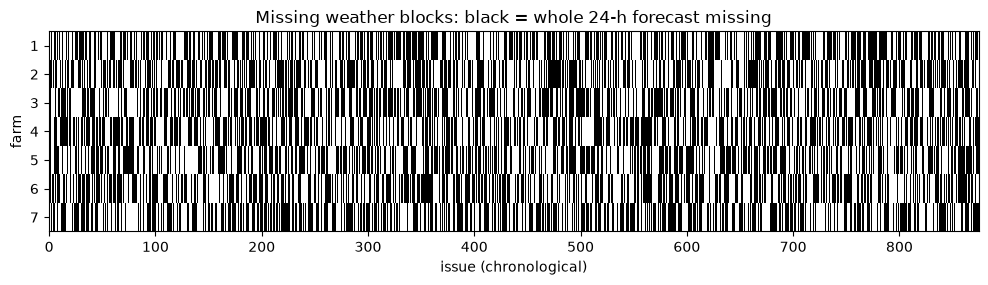

In [8]:
m = train.ws.isna()
blk = m.groupby([train.farm, train.issue_time]).mean()
print(f"weather missing: train {m.mean():.3f}, test {test.ws.isna().mean():.3f}")
print(f"(farm, issue) blocks fully missing / fully present / partial: "
      f"{(blk==1).mean():.3f} / {(blk==0).mean():.3f} / {((blk>0)&(blk<1)).mean():.3f}")
M = train.assign(miss=m).groupby(["issue_time", "farm"]).miss.first().unstack()
off = M.astype(float).corr().values[~np.eye(7, dtype=bool)]
print(f"missingness correlation between farms: max |r| = {np.abs(off).max():.2f}")
print("test missing rate by farm:", test.ws.isna().groupby(test.farm).mean().round(2).to_dict())
print("mean power | weather present vs missing:",
      train.groupby(train.ws.notna()).power.mean().round(3).to_dict())
gap = (np.hypot(train.u, train.v) - train.ws).abs().max()
print(f"max |sqrt(u^2+v^2) - ws| = {gap:.4f}  -> ws is derived from (u, v)")
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.imshow(M.T.astype(float).values, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set(yticks=range(7), yticklabels=FARMS, xlabel="issue (chronological)", ylabel="farm",
       title="Missing weather blocks: black = whole 24-h forecast missing")
plt.show()

**Finding.** Weather is missing in whole 24-hour (farm, issue) blocks, about 50% of the time, independently across farms and unrelated to power. In the test set, farms 6 and 7 are missing more often (≈ 60%).

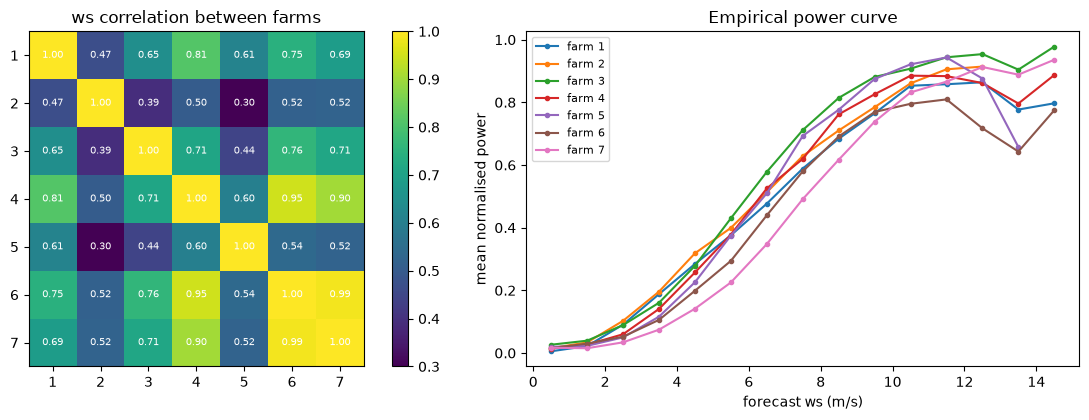

corr(power, ws) by farm: {1: 0.727, 2: 0.695, 3: 0.812, 4: 0.797, 5: 0.78, 6: 0.815, 7: 0.831}
mean power by month: {1: 0.358, 2: 0.355, 3: 0.315, 4: 0.368, 5: 0.243, 6: 0.179, 7: 0.139, 8: 0.167, 9: 0.242, 10: 0.314, 11: 0.354, 12: 0.383}


In [10]:
WS = train.pivot_table(index=["issue_time", "target_time"], columns="farm", values="ws")
a = train.dropna(subset=["ws"]).copy()
a["bin"] = pd.cut(a.ws, np.arange(0, 16, 1))
curve = a.groupby(["bin", "farm"], observed=True).power.mean().unstack()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
im = ax[0].imshow(WS.corr(), vmin=0.3, vmax=1, cmap="viridis")
ax[0].set(xticks=range(7), yticks=range(7), xticklabels=FARMS, yticklabels=FARMS, title="ws correlation between farms")
for i in range(7):
    for j in range(7):
        ax[0].text(j, i, f"{WS.corr().values[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
plt.colorbar(im, ax=ax[0])
for f in FARMS:
    ax[1].plot([b.mid for b in curve.index], curve[f], marker="o", ms=3, label=f"farm {f}")
ax[1].set(xlabel="forecast ws (m/s)", ylabel="mean normalised power", title="Empirical power curve")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()
print("corr(power, ws) by farm:", a.groupby("farm").apply(lambda d: round(d.power.corr(d.ws), 3)).to_dict())
print("mean power by month:", train.groupby(train.target_time.dt.month).power.mean().round(3).to_dict())

**Findings.**
- Farms {4, 6, 7} share almost the same forecast (r = 0.90–0.99). Farms 2 and 5 are loners (r ≈ 0.3–0.5), so a plain cross-farm mean imputes them poorly.
- The power curve is S-shaped, different for each farm, and flattens at about 10–12 m/s.
- Season matters a lot (monthly mean power 0.14–0.38). The test set is Apr–Jun 2012.

## 3. Chronological validation protocol
Four expanding-window folds split on `issue_time`. Fold F1 (Apr–Jun 2011) is the same season as the test set. A model is preferred only if it improves the mean fold RMSE consistently (most folds), backed by a paired issue-level bootstrap.

In [13]:
rows = []
for name, trn, val in iter_folds(train):
    c = trn.power.mean()
    rows.append({"fold": name, "train_rows": len(trn), "val_rows": len(val),
                 "val_issues": val.issue_time.nunique(),
                 "constant_baseline_RMSE": rmse(val.power, np.full(len(val), c))})
pd.DataFrame(rows).set_index("fold").round(4)

,train_rows,val_rows,val_issues,constant_baseline_RMSE
fold,,,,
F1_2011Q2,101892,9828,65,0.2881
F2_2011Q3,111720,9996,66,0.2280
F3_2011Q4,121716,9996,66,0.3271
F4_2012Q1,131712,9828,65,0.3626


## 4. Experiment log
Out-of-fold (OOF) predictions saved by the experiment scripts (`exp00_crossfarm_cv.py`, `exp01_learned_impute_cv.py`, `exp01b_seed_check.py`, `exp02_spatial_cv.py`). All use the same folds and a fixed 10-epoch protocol (no epoch chosen on validation).

In [15]:
EXPS = [("Exp00 cross-farm mean + MLP (seed 42)", "oof/exp00_oof.csv"),
        ("Exp01 learned imputation, hypot (seed 42)", "oof/exp01_hypot_oof.csv"),
        ("Exp01 learned imputation, rescaled (seed 42)", "oof/exp01_rescaled_oof.csv"),
        ("Exp00, 3-seed average", "oof/exp00_3seed_oof.csv"),
        ("Exp01-rescaled, 3-seed average", "oof/exp01r_3seed_oof.csv"),
        ("Exp02 spatial NN, mask only, 3-seed", "oof/exp02_maskonly_3seed_oof.csv"),
        ("Exp02 spatial NN + rescaled, 3-seed", "oof/exp02_rescaled_3seed_oof.csv")]
log = []
for label, path in EXPS:
    if not os.path.exists(path):
        print("missing (skipped):", path); continue
    o = pd.read_csv(path); w0 = o.weather_available == 0
    st = fold_stats(o)
    log.append({"experiment": label, "mean_CV": st["mean_cv"], "pooled_OOF": st["pooled"],
                **{k: st[k] for k in ["F1_2011Q2", "F2_2011Q3", "F3_2011Q4", "F4_2012Q1"]},
                "wx_present": rmse(o.power[~w0], o.pred[~w0]), "wx_missing": rmse(o.power[w0], o.pred[w0])})
# [P2 copy] skip cleanly if the optional oof/ experiment logs (from the exp*.py scripts) are absent
if log:
    log = pd.DataFrame(log).set_index("experiment")
    display(log.round(5))
else:
    print("experiment-log OOF files not present - section 4 table skipped (see the scripts exp00-exp02)")

,mean_CV,pooled_OOF,F1_2011Q2,F2_2011Q3,F3_2011Q4,F4_2012Q1,wx_present,wx_missing
experiment,,,,,,,,
Exp00 cross-farm mean + MLP (seed 42),0.17836,0.18071,0.17547,0.13230,0.19217,0.21352,0.15143,0.20630
"Exp01 learned imputation, hypot (seed 42)",0.17671,0.17902,0.17619,0.13021,0.18998,0.21045,0.14832,0.20562
"Exp01 learned imputation, rescaled (seed 42)",0.17547,0.17785,0.16992,0.13007,0.19279,0.20909,0.14835,0.20354
"Exp00, 3-seed average",0.17608,0.17857,0.16889,0.13128,0.19001,0.21415,0.14975,0.20376
"Exp01-rescaled, 3-seed average",0.17639,0.17882,0.16917,0.13182,0.19116,0.21341,0.14912,0.20468
"Exp02 spatial NN, mask only, 3-seed",0.18000,0.18251,0.17394,0.13439,0.19180,0.21987,0.15573,0.20623
"Exp02 spatial NN + rescaled, 3-seed",0.17342,0.17555,0.16778,0.13157,0.18640,0.20793,0.14782,0.19988


Public leaderboard scores of earlier submissions (for reference; the private LB is the target):

| submission | public LB RMSE |
|---|---|
| Original MLP | 0.22227 |
| HistGradientBoosting | 0.22366 |
| MLP + HGB ensemble | 0.22232 |
| Cross-farm imputation + MLP (`nn_crossfarm.csv`) | 0.19804 |

**Lessons from the log**
- Exp01 (learned imputation) cut held-out ws imputation error by 20% (1.61 → 1.29 m/s, rescaled variant). Its single-seed power gain, however, disappeared after averaging 3 matched seeds. With one seed, the score moves ±0.004 between epochs.
- Exp02 lets the network see all seven farms plus their availability mask, and gives each farm its own output head. It is the first change that holds up against the 3-seed baseline. Without the imputer (mask only), the spatial network is worse, so the learned imputation matters as an *input* to the spatial network.

In [17]:
def paired(a_path, b_path, la, lb):
    a = pd.read_csv(a_path); b = pd.read_csv(b_path)[["id", "pred"]].rename(columns={"pred": "b"})
    m = a.rename(columns={"pred": "a"}).merge(b, on="id", validate="one_to_one")
    print(f"\n=== {lb} vs {la} ===")
    return paired_report(m, "a", "b", la, lb)
if os.path.exists("oof/exp00_3seed_oof.csv") and os.path.exists("oof/exp02_rescaled_3seed_oof.csv"):
    paired("oof/exp00_3seed_oof.csv", "oof/exp02_rescaled_3seed_oof.csv", "exp00_3seed", "exp02_rescaled")
    paired("oof/exp01r_3seed_oof.csv", "oof/exp02_rescaled_3seed_oof.csv", "exp01r_3seed", "exp02_rescaled")


=== exp02_rescaled vs exp00_3seed ===
           exp00_3seed  exp02_rescaled    delta  d_present  d_missing
fold                                                                 
F1_2011Q2      0.16889         0.16778 -0.00110   -0.00786    0.00453
F2_2011Q3      0.13128         0.13157  0.00029   -0.00201    0.00218
F3_2011Q4      0.19001         0.18640 -0.00361    0.00213   -0.00810
F4_2012Q1      0.21415         0.20793 -0.00622   -0.00053   -0.01009
folds improved: 3/4   mean-fold delta: -0.00266
pooled MSE diff (exp02_rescaled - exp00_3seed): -0.001067  95% CI [-0.002624, +0.000449]
per-farm pooled RMSE delta: {1: -0.0092, 2: 0.0009, 3: 0.0007, 4: -0.0067, 5: 0.0012, 6: -0.0044, 7: -0.007}

=== exp02_rescaled vs exp01r_3seed ===
           exp01r_3seed  exp02_rescaled    delta  d_present  d_missing
fold                                                                  
F1_2011Q2       0.16917         0.16778 -0.00138   -0.00510    0.00165
F2_2011Q3       0.13182         0.13157 -0

## 5. Final model – executed chronological cross-validation
Spatial NN: for each row (farm *f*, slot), the inputs are u, v, ws and direction for **all seven farms** at the same issue/target time, each farm's observed-weather flag, a copy of farm *f*'s own block, the number of observed farms, time features, and a farm one-hot. A shared trunk (256-128-64, dropout 0.1) feeds **7 farm-specific heads**. Missing weather comes from the fold-trained learned imputer (rescaled: direction from the imputed vector, magnitude from the imputed ws).

In [19]:
BLOCK = ["u", "v", "ws", "dsin", "dcos"]
SEEDS = [42, 43, 44]

def spatial_frame(d_imp, d_raw):
    d = d_imp.copy()
    obs = d_raw.ws.notna().values
    d["a"] = obs.astype(np.float32)
    d["dsin"], d["dcos"] = np.sin(np.arctan2(d.v, d.u)), np.cos(np.arctan2(d.v, d.u))
    w = d.pivot_table(index=KEY, columns="farm", values=BLOCK + ["a"])
    w = w.reindex(pd.MultiIndex.from_frame(d[KEY].drop_duplicates()))
    w.columns = [f"{c}_{g}" for c, g in w.columns]
    w["n_obs"] = w[[f"a_{g}" for g in FARMS]].sum(1)
    keep = ["id", "farm"] + KEY + ["horizon", "hour_sin", "hour_cos", "month_sin", "month_cos",
                                   "weather_available"] + (["power"] if "power" in d else []) + BLOCK + ["a"]
    out = d[keep].rename(columns={c: f"self_{c}" for c in BLOCK + ["a"]})
    out = out.merge(w.reset_index(), on=KEY, how="left", validate="many_to_one")
    assert len(out) == len(d)
    return out

def feature_cols():
    return ([f"{c}_{g}" for g in FARMS for c in BLOCK + ["a"]] + [f"self_{c}" for c in BLOCK + ["a"]]
            + ["n_obs", "horizon", "hour_sin", "hour_cos", "month_sin", "month_cos"])

def to_xy(df, stats):
    X = ((df[feature_cols()] - stats[0]) / stats[1]).fillna(0.0).to_numpy(np.float32)
    return np.hstack([X, np.eye(7, dtype=np.float32)[df.farm.values - 1]]), (df.farm.values - 1).astype(np.int64)

class SpatialNet(nn.Module):
    def __init__(self, k):
        super().__init__()
        self.trunk = nn.Sequential(nn.Linear(k, 256), nn.ReLU(), nn.Dropout(0.1),
                                   nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.1),
                                   nn.Linear(128, 64), nn.ReLU())
        self.heads = nn.Linear(64, 7)
    def forward(self, x, farm_idx):
        return self.heads(self.trunk(x)).gather(1, farm_idx.view(-1, 1))

In [20]:
t0 = time.time()
seed_preds, meta, curves = {s: [] for s in SEEDS}, [], {}
for name, trn, val in iter_folds(train):
    trn_i, val_i = cached_rescaled(name, trn, val)          # imputers fit on fold-train only
    ftr, fva = spatial_frame(trn_i, trn), spatial_frame(val_i, val)
    stats = (ftr[feature_cols()].mean(), ftr[feature_cols()].std().replace(0, 1))   # fold-train only
    Xtr, Ftr = to_xy(ftr, stats); Xva, Fva = to_xy(fva, stats)
    meta.append(fva[["id", "farm", "issue_time", "target_time", "weather_available", "power"]].assign(fold=name))
    for s in SEEDS:
        p, curve, _ = train_eval(lambda: SpatialNet(Xtr.shape[1]), Xtr, ftr.power.values, Xva,
                                 fva.power.values, seed=s, ftr=Ftr, fva=Fva)
        seed_preds[s].append(p); curves[(name, s)] = curve
        print(f"{name} seed {s}: fixed-10-epoch val RMSE {curve[-1]:.5f}")
meta = pd.concat(meta).reset_index(drop=True)
oof_final = meta.assign(pred=np.mean([np.concatenate(seed_preds[s]) for s in SEEDS], axis=0))
os.makedirs("oof", exist_ok=True)
oof_final.to_csv("oof/notebook_final_oof.csv", index=False)
print(f"CV time: {(time.time() - t0) / 60:.1f} min")

  [F1_2011Q2] training imputers (cached afterwards)
F1_2011Q2 seed 42: fixed-10-epoch val RMSE 0.18484
F1_2011Q2 seed 43: fixed-10-epoch val RMSE 0.16879
F1_2011Q2 seed 44: fixed-10-epoch val RMSE 0.17792
  [F2_2011Q3] training imputers (cached afterwards)
F2_2011Q3 seed 42: fixed-10-epoch val RMSE 0.13319
F2_2011Q3 seed 43: fixed-10-epoch val RMSE 0.13501
F2_2011Q3 seed 44: fixed-10-epoch val RMSE 0.13302
  [F3_2011Q4] training imputers (cached afterwards)
F3_2011Q4 seed 42: fixed-10-epoch val RMSE 0.18845
F3_2011Q4 seed 43: fixed-10-epoch val RMSE 0.19169
F3_2011Q4 seed 44: fixed-10-epoch val RMSE 0.18597
  [F4_2012Q1] training imputers (cached afterwards)
F4_2012Q1 seed 42: fixed-10-epoch val RMSE 0.20905
F4_2012Q1 seed 43: fixed-10-epoch val RMSE 0.21236
F4_2012Q1 seed 44: fixed-10-epoch val RMSE 0.21464
CV time: 4.7 min


F1_2011Q2 seed 44: fixed-10-epoch val RMSE 0.17131
  [F2_2011Q3] training imputers (cached afterwards)


F2_2011Q3 seed 42: fixed-10-epoch val RMSE 0.13422


F2_2011Q3 seed 43: fixed-10-epoch val RMSE 0.13217


F2_2011Q3 seed 44: fixed-10-epoch val RMSE 0.13214
  [F3_2011Q4] training imputers (cached afterwards)


F3_2011Q4 seed 42: fixed-10-epoch val RMSE 0.18977


F3_2011Q4 seed 43: fixed-10-epoch val RMSE 0.18987


F3_2011Q4 seed 44: fixed-10-epoch val RMSE 0.18665
  [F4_2012Q1] training imputers (cached afterwards)


F4_2012Q1 seed 42: fixed-10-epoch val RMSE 0.21130


F4_2012Q1 seed 43: fixed-10-epoch val RMSE 0.21006


F4_2012Q1 seed 44: fixed-10-epoch val RMSE 0.21452
CV time: 5.9 min



===== FINAL MODEL (Exp02 spatial NN + rescaled imputation, 3-seed average) =====
              rmse  rmse_wx_present  rmse_wx_missing     n
fold                                                      
F1_2011Q2  0.16775          0.14239          0.19170  9828
F2_2011Q3  0.13097          0.11641          0.14421  9996
F3_2011Q4  0.18510          0.15649          0.21104  9996
F4_2012Q1  0.20866          0.17079          0.23832  9828
mean fold RMSE   : 0.17312  (std 0.03272)
pooled OOF RMSE  : 0.17530
F1 (Apr-Jun) RMSE: 0.16775
per-farm pooled RMSE: {1: 0.1492, 2: 0.1966, 3: 0.2055, 4: 0.1594, 5: 0.1992, 6: 0.1502, 7: 0.1559}

OVERALL VALIDATION RMSE (pooled OOF, 4 chronological folds): 0.17530
weather present: 0.14752 | weather missing: 0.19966
single-seed pooled RMSE: {42: 0.18091, 43: 0.17917, 44: 0.18013}
best-epoch mean RMSE (optimistic, epoch picked on validation; NOT used): 0.16987


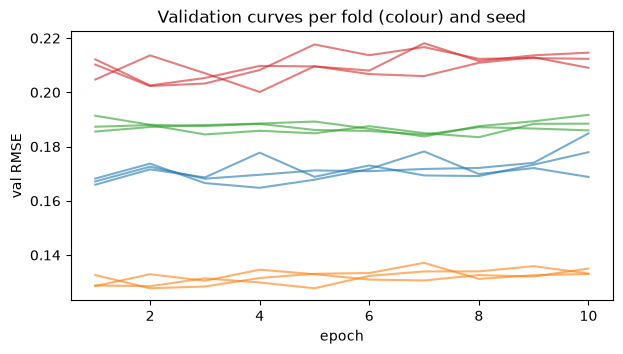

In [21]:
res = summarize(oof_final, "FINAL MODEL (Exp02 spatial NN + rescaled imputation, 3-seed average)")
w0 = oof_final.weather_available == 0
print(f"\nOVERALL VALIDATION RMSE (pooled OOF, 4 chronological folds): {rmse(oof_final.power, oof_final.pred):.5f}")
print(f"weather present: {rmse(oof_final.power[~w0], oof_final.pred[~w0]):.5f} | "
      f"weather missing: {rmse(oof_final.power[w0], oof_final.pred[w0]):.5f}")
per_seed = {s: rmse(meta.power, np.concatenate(seed_preds[s])) for s in SEEDS}
print("single-seed pooled RMSE:", {k: round(v, 5) for k, v in per_seed.items()})
print("best-epoch mean RMSE (optimistic, epoch picked on validation; NOT used):",
      round(float(np.mean([min(c) for c in curves.values()])), 5))
fig, ax = plt.subplots(figsize=(7, 3.5))
for (name, s), c in curves.items():
    ax.plot(range(1, 11), c, color=f"C{list(res.index).index(name)}", alpha=0.6)
ax.set(xlabel="epoch", ylabel="val RMSE", title="Validation curves per fold (colour) and seed"); plt.show()

## 6. Final training on all training data and test prediction
Imputers, fallback medians and standardisation are fit on `train.csv` only. The same architecture is trained with the same fixed 10-epoch protocol for seeds 42/43/44, and the three predictions are averaged.

In [23]:
t0 = time.time()
imp_full = FarmImputers().fit(wide(train))
train_i, test_i = learned_impute(train, imp_full, train), learned_impute(test, imp_full, train)
obs = test.ws.notna()
assert test_i[WEATHER].notna().all().all() and np.allclose(test_i.loc[obs, "u"], test.loc[obs, "u"])
ftr, fte = spatial_frame(train_i, train), spatial_frame(test_i, test)
stats = (ftr[feature_cols()].mean(), ftr[feature_cols()].std().replace(0, 1))
Xtr, Ftr = to_xy(ftr, stats); Xte, Fte = to_xy(fte, stats)
preds = []
for s in SEEDS:
    p, _, _ = train_eval(lambda: SpatialNet(Xtr.shape[1]), Xtr, ftr.power.values, Xte,
                         np.zeros(len(Xte), np.float32), seed=s, ftr=Ftr, fva=Fte)
    preds.append(p); print(f"seed {s}: test mean prediction {p.mean():.4f}")
mu = np.clip(np.mean(preds, axis=0), 0, 1)
sub = sample[["id"]].merge(pd.DataFrame({"id": fte["id"].values, "mu": mu}), on="id", how="left", validate="one_to_one")
assert len(sub) == 9408 and list(sub.columns) == ["id", "mu"]
assert (sub.id.values == sample.id.values).all() and np.isfinite(sub.mu).all() and sub.mu.between(0, 1).all()
sub.to_csv("final_submission.csv", index=False)
print(f"wrote final_submission.csv ({len(sub)} rows) in {(time.time() - t0) / 60:.1f} min")
print(sub.mu.describe().round(4))
if os.path.exists("exp02_spatial_submission.csv"):
    s2 = pd.read_csv("exp02_spatial_submission.csv")
    print("max |diff| vs exp02_spatial_submission.csv:", float(np.abs(s2.mu.values - sub.mu.values).max()))
sub.head()

seed 42: test mean prediction 0.2415
seed 43: test mean prediction 0.2344
seed 44: test mean prediction 0.2404
wrote final_submission.csv (9408 rows) in 1.3 min
count    9408.0000
mean        0.2388
std         0.2107
min         0.0000
25%         0.0776
50%         0.1628
75%         0.3445
max         0.9836
Name: mu, dtype: float64
max |diff| vs exp02_spatial_submission.csv: 0.0806029709037781


,id,mu
0,245754,0.116361
1,246677,0.043265
2,249992,0.106072
3,250368,0.065545
4,246581,0.023300


## 7. Conclusions & limitations
- **Selected model:** Exp02 spatial NN + learned rescaled imputation, 3-seed average (see the overall validation RMSE in §5).
- **Where the gain comes from:** using all seven farms jointly with availability masks and farm-specific heads. The learned imputer helps only as an input to this network.
- **Uncertainty:** the paired 95% bootstrap CI against the 3-seed baseline still slightly overlaps zero. The gain is concentrated in the winter folds (F3, F4). In F1 (same season as the test set), weather-present rows improve but weather-missing rows get slightly worse. We therefore expect a smaller gain on the test period than the mean CV suggests.
- **Not done (time):** a 24-step Transformer over the issue sequence, a mixture of experts, learning-rate decay / more seeds, and an OOF residual correction. These are the natural next steps.

In [25]:
print(f"total notebook runtime: {(time.time() - T0) / 60:.1f} min")

total notebook runtime: 6.0 min


## 8. Probabilistic predictions: P1 (post-hoc σ) vs P2 (probabilistic neural network)

The competition scores a Gaussian predictive distribution per row, `id, mu, sigma`.

**Metric used here (reconstructed, not yet confirmed against the official formula):**
$$\text{score}=\frac1N\sum_i\Big[\tfrac12\log(2\pi s_i^2)+\frac{(y_i-\mu_i)^2}{2s_i^2}\Big]+5\cdot\frac1N\sum_i\big(y_i^2-(\mu_i^2+s_i^2)\big)^2,\qquad s_i=\max(\sigma_i,0.01).$$

**Hypotheses.**
* **P1:** the Exp02 mean model is good, and a σ that depends on the predicted mean, weather availability and farm will beat any constant σ.
* **P2:** the test period (2012Q2) has fewer farms with observed weather per slot ("donors") than training. Two consequences follow:
  * Training the spatial NN under **simulated donor loss** should improve μ where donors are scarce.
  * A σ head that sees donor count, own-weather availability and μ should model that uncertainty directly inside the network.

In [27]:
AUX_WEIGHT, SIGMA_FLOOR = 5.0, 0.01

def prob_components(y, mu, sigma):
    y, mu, sigma = (np.asarray(a, float) for a in (y, mu, sigma))
    assert np.isfinite(mu).all() and np.isfinite(sigma).all() and (sigma > 0).all()
    s2 = np.maximum(sigma, SIGMA_FLOOR) ** 2
    return 0.5 * np.log(2 * np.pi * s2) + (y - mu) ** 2 / (2 * s2), (y ** 2 - (mu ** 2 + s2)) ** 2

def prob_score(y, mu, sigma):
    nll, m2 = prob_components(y, mu, sigma)
    return float(nll.mean() + AUX_WEIGHT * m2.mean())

test["n_obs"] = test.groupby(KEY).ws.transform(lambda s: s.notna().sum())
print("donors per slot - train:", round(train.groupby(KEY).ws.transform(lambda s: s.notna().sum()).mean(), 2),
      "| test:", round(test.n_obs.mean(), 2), "| test share with <=3 donors:", round((test.n_obs <= 3).mean(), 3))

donors per slot - train: 3.52 | test: 3.29 | test share with <=3 donors: 0.571


### 8.1 Methods

**P1, grouped σ (post-hoc, mean model unchanged).**
* Uses the squared residuals of the Exp02 out-of-fold predictions.
* Shrunk in three levels: global → weather_available × μ-bin → × farm, with pseudo-count k = 50.
* Interpolated linearly in μ, then multiplied by one scale factor that is fitted on the training rows.

**Donor dropout.**
* Applied to fold-train data only.
* Each *observed* (farm, issue) 24-hour weather block is hidden with probability 0.35, at least one observed farm is kept per issue, and the hidden blocks are re-imputed with that fold's learned imputer.
* This mimics the real block-wise missingness. Two augmented copies are made, and in each epoch every row comes from an augmented copy with probability 0.5, so training steps match the control.

**Network.**
* Same inputs and trunk as Exp02: all 7 farms' (u, v, ws, direction) plus observed flags, a copy of the row's own farm, donor count, horizon and time features, and a farm one-hot. The trunk is 256-128-64 with dropout 0.1.
* **μ head:** 7 farm-specific outputs.
* **σ head:** an MLP on [trunk features, donor count, own-weather flag, μ (detached)] with 7 farm-specific outputs. σ = softplus(·) + 0.01.

**Loss and training.**
* *Joint (chosen):* 2 MSE warm-up epochs, then 8 epochs on the metric loss for both heads (NLL without its constant + 5 × second-moment term).
* Adam (lr 1e-3, weight decay 1e-4), batch 512, seeds 42/43/44, fixed epochs (no early stopping).

**Seed ensemble.** μ = mean of μ_s; σ² = mean of σ_s² + variance of μ_s (Gaussian mixture moments).

**σ calibration.**
* The σ head is fitted on training residuals, which are smaller than out-of-sample ones, so raw σ is too small.
* One temperature factor c multiplies σ. Here c is fitted **only on folds other than the one being scored**: other folds (LOFO) or strictly earlier folds (past-only).
* For the submission, c is fitted on all four out-of-fold folds.

In [29]:
# ---- P2 helpers (verbatim copy of p2/p2_lib.py; names prefixed p2_ to keep sections 1-6 intact)
import os, pickle
os.makedirs("cache_p2", exist_ok=True)
BLOCK = ["u", "v", "ws", "dsin", "dcos"]
SIG_FLOOR = 0.01



# ------------------------------------------------------------ data
def p2_fold_data(name, trn, val):
    """Fold imputer fit on fold-train only (as in exp02); cached with the imputer object."""
    path = f"cache_p2/{name}.pkl"
    if os.path.exists(path):
        with open(path, "rb") as fh:
            imp, trn_i, val_i = pickle.load(fh)
        if len(trn_i) == len(trn) and len(val_i) == len(val):
            return imp, trn_i, val_i
    imp = FarmImputers().fit(wide(trn))
    trn_i, val_i = learned_impute(trn, imp, trn), learned_impute(val, imp, trn)
    with open(path, "wb") as fh:
        pickle.dump((imp, trn_i, val_i), fh)
    return imp, trn_i, val_i


def p2_frame(d_imp, d_raw):
    """Copied from exp02_submission.py (rescaled variant) + explicit n_obs/self_a kept."""
    d = d_imp.copy()
    obs = d_raw.ws.notna().values
    d["a"] = obs.astype(np.float32)
    d["dsin"], d["dcos"] = np.sin(np.arctan2(d.v, d.u)), np.cos(np.arctan2(d.v, d.u))
    w = d.pivot_table(index=KEY, columns="farm", values=BLOCK + ["a"])
    w = w.reindex(pd.MultiIndex.from_frame(d[KEY].drop_duplicates()))
    w.columns = [f"{c}_{g}" for c, g in w.columns]
    w["n_obs"] = w[[f"a_{g}" for g in FARMS]].sum(1)
    keep = ["id", "farm"] + KEY + ["horizon", "hour_sin", "hour_cos", "month_sin", "month_cos"] \
        + (["power"] if "power" in d else []) + BLOCK + ["a"]
    out = d[keep].rename(columns={c: f"self_{c}" for c in BLOCK + ["a"]})
    out = out.merge(w.reset_index(), on=KEY, how="left", validate="many_to_one")
    assert len(out) == len(d) and (out.id.values == d.id.values).all()
    return out


def p2_cols():
    return ([f"{c}_{g}" for g in FARMS for c in BLOCK + ["a"]] + [f"self_{c}" for c in BLOCK + ["a"]]
            + ["n_obs", "horizon", "hour_sin", "hour_cos", "month_sin", "month_cos"])


def p2_x(df, stats):
    X = ((df[p2_cols()] - stats[0]) / stats[1]).fillna(0.0).to_numpy(np.float32)
    return np.hstack([X, np.eye(7, dtype=np.float32)[df.farm.values - 1]])


def donor_dropout(trn_raw, imp, fit_df, p, rng):
    """Hide each OBSERVED farm-issue weather block with prob p (whole 24h blocks, like the real
    missingness), keeping >=1 observed farm per issue; re-impute hidden blocks with the fold imputer."""
    d = trn_raw.copy()
    blk = d.groupby(["issue_time", "farm"]).ws.apply(lambda s: s.notna().all()).unstack()
    hide = (rng.random(blk.shape) < p) & blk.values
    still = blk.values & ~hide
    for i in np.where(still.sum(1) == 0)[0]:          # keep at least one observed farm
        obs_cols = np.where(blk.values[i])[0]
        if len(obs_cols):
            hide[i, rng.choice(obs_cols)] = False
    H = pd.DataFrame(hide, index=blk.index, columns=blk.columns).stack().rename("hide").reset_index()
    d = d.merge(H, on=["issue_time", "farm"], how="left")
    d.loc[d.hide.fillna(False).astype(bool), ["u", "v", "ws"]] = np.nan
    d = d.drop(columns="hide")
    d["weather_available"] = d[["u", "v", "ws"]].notna().all(axis=1).astype(int)
    assert len(d) == len(trn_raw) and (d.id.values == trn_raw.id.values).all()
    return p2_frame(learned_impute(d, imp, fit_df), d)


# ------------------------------------------------------------ models
class P2MeanNet(nn.Module):                        # identical to exp02
    def __init__(self, k):
        super().__init__()
        self.trunk = nn.Sequential(nn.Linear(k, 256), nn.ReLU(), nn.Dropout(0.1),
                                   nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.1),
                                   nn.Linear(128, 64), nn.ReLU())
        self.heads = nn.Linear(64, 7)

    def forward(self, x, f):
        return self.heads(self.trunk(x)).gather(1, f.view(-1, 1)).squeeze(1)


class ProbSpatialNet(P2MeanNet):
    """Same trunk/mu heads + per-farm sigma head on [trunk, n_obs, self_a, mu.detach()]."""
    def __init__(self, k, i_nobs, i_selfa):
        super().__init__(k)
        self.i_nobs, self.i_selfa = i_nobs, i_selfa
        self.sig = nn.Sequential(nn.Linear(64 + 3, 32), nn.ReLU(), nn.Linear(32, 7))

    def forward(self, x, f):
        h = self.trunk(x)
        mu = self.heads(h).gather(1, f.view(-1, 1)).squeeze(1)
        z = torch.cat([h, x[:, [self.i_nobs, self.i_selfa]], mu.detach().unsqueeze(1)], 1)
        s = nn.functional.softplus(self.sig(z).gather(1, f.view(-1, 1)).squeeze(1)) + SIG_FLOOR
        return mu, s


def metric_loss(y, mu, s):
    """Reconstructed competition loss (NLL without constant + 5 * second-moment)."""
    return (torch.log(s) + (y - mu) ** 2 / (2 * s ** 2) + 5.0 * (y ** 2 - mu ** 2 - s ** 2) ** 2).mean()


def p2_train(model, Xs, F, y, seed, epochs, mode, q_aug=0.5, lr=1e-3, wd=1e-4, warm=0, params=None, freeze_trunk=False):
    """Xs: list [X_orig, X_aug1, ...] row-aligned. Each epoch every row is drawn from the original
    with prob 1-q_aug, else from a random augmented copy (same steps per epoch as the control).
    mode: 'mse' | 'metric' (prob model) ; warm: epochs of MSE before switching to metric."""
    seed_everything(seed)
    g = np.random.default_rng(seed)
    opt = torch.optim.Adam(params if params is not None else model.parameters(), lr=lr, weight_decay=wd)
    Xt = [torch.from_numpy(x) for x in Xs]
    Ft, yt = torch.from_numpy(F), torch.from_numpy(y.astype(np.float32))
    n = len(y)
    for ep in range(epochs):
        src = np.zeros(n, int) if len(Xs) == 1 else np.where(g.random(n) < q_aug, g.integers(1, len(Xs), n), 0)
        perm = torch.from_numpy(g.permutation(n))
        model.train()
        if freeze_trunk:
            model.trunk.eval()
        for b in range(0, n, 512):
            i = perm[b:b + 512]
            si = src[i.numpy()]
            xb = torch.empty((len(i), Xs[0].shape[1]))
            for k in np.unique(si):
                m = si == k
                xb[torch.from_numpy(m)] = Xt[k][i[torch.from_numpy(m)]]
            fb, yb = Ft[i], yt[i]
            opt.zero_grad()
            if mode == "mse" or ep < warm:
                out = model(xb, fb)
                mu = out[0] if isinstance(out, tuple) else out
                loss = nn.functional.mse_loss(mu, yb)
            else:
                mu, s = model(xb, fb)
                loss = metric_loss(yb, mu, s)
            loss.backward()
            opt.step()
    model.eval()
    return model


@torch.no_grad()
def p2_predict(model, X, F):
    out = model(torch.from_numpy(X), torch.from_numpy(F))
    if isinstance(out, tuple):
        return np.clip(out[0].numpy(), 0, 1), out[1].numpy()
    return np.clip(out.numpy(), 0, 1), None

In [30]:
# ---- P1 grouped sigma estimator (verbatim copy of p1/sigma_models.py, GroupedSigma part)
from scipy.optimize import minimize, minimize_scalar
FLOOR, W_AUX, SIG_MAX = 0.01, 5.0, 0.6
BIN_EDGES = np.array([0.0, 0.03, 0.07, 0.12, 0.2, 0.3, 0.45, 0.6, 0.8, 1.0001])
KNOTS = [0.03, 0.07, 0.12, 0.2, 0.3, 0.45, 0.6, 0.8]


def _score_vec(y, mu, s):
    s2 = np.maximum(s, FLOOR) ** 2
    return 0.5 * np.log(2 * np.pi * s2) + (y - mu) ** 2 / (2 * s2) + W_AUX * (y ** 2 - mu ** 2 - s2) ** 2


def _score(y, mu, s):
    return float(_score_vec(y, mu, s).mean())


class GroupedSigma:
    def __init__(self, k=300.0, use_farm=True, scale=True):
        self.k, self.use_farm, self.scale = k, use_farm, scale

    def fit(self, df):
        r2 = (df.y - df.mu).values ** 2
        b = np.clip(np.digitize(df.mu.values, BIN_EDGES) - 1, 0, len(BIN_EDGES) - 2)
        g0 = r2.mean()
        nb = len(BIN_EDGES) - 1
        self.v1 = np.full((2, nb), g0)
        self.v2 = np.full((2, nb, 8), np.nan)
        for w in (0, 1):
            for i in range(nb):
                m = (df.w.values == w) & (b == i)
                n = m.sum()
                self.v1[w, i] = (r2[m].sum() + self.k * g0) / (n + self.k)
                for f in range(1, 8):
                    mf = m & (df.farm.values == f)
                    nf = mf.sum()
                    self.v2[w, i, f] = (r2[mf].sum() + self.k * self.v1[w, i]) / (nf + self.k)
        self.centres = np.array([df.mu.values[(b == i)].mean() if (b == i).any() else (BIN_EDGES[i] + BIN_EDGES[i + 1]) / 2
                                 for i in range(nb)])
        self.c = 1.0
        if self.scale:
            raw = self._raw(df)
            self.c = minimize_scalar(lambda c: _score(df.y.values, df.mu.values, np.clip(c * raw, FLOOR, SIG_MAX)),
                                     bounds=(0.5, 2.0), method="bounded").x
        return self

    def _raw(self, df):
        out = np.empty(len(df))
        mu, w, farm = df.mu.values, df.w.values, df.farm.values
        for wv in (0, 1):
            for f in range(1, 8):
                m = (w == wv) & (farm == f)
                if not m.any():
                    continue
                tab = self.v2[wv, :, f] if self.use_farm else self.v1[wv]
                out[m] = np.sqrt(np.interp(mu[m], self.centres, tab))
        return out

    def predict(self, df):
        return np.clip(self.c * self._raw(df), FLOOR, SIG_MAX)

### 8.2 Chronological cross-validation of P2 (same four expanding folds and seeds as Exp02)
The imputers, standardisation, donor-dropout copies and networks are all built from the fold's training part only. Runtime is about 15 minutes on CPU.

In [32]:
t0 = time.time()
P2_SEEDS, P_HIDE, N_AUG = [42, 43, 44], 0.35, 2
cols2 = p2_cols()
i_nobs, i_selfa = cols2.index("n_obs"), cols2.index("self_a")
p2_parts = []
for name, trn, val in iter_folds(train):
    imp_f, trn_i, val_i = p2_fold_data(name, trn, val)
    ftr, fva = p2_frame(trn_i, trn), p2_frame(val_i, val)
    st = (ftr[cols2].mean(), ftr[cols2].std().replace(0, 1))
    Xtr, Xva = p2_x(ftr, st), p2_x(fva, st)
    Ftr, Fva = (ftr.farm.values - 1).astype(np.int64), (fva.farm.values - 1).astype(np.int64)
    rng_aug = np.random.default_rng(1000 + int(name[1]))
    Xaug = [p2_x(donor_dropout(trn, imp_f, trn, P_HIDE, rng_aug), st) for _ in range(N_AUG)]
    mus, sgs = [], []
    for s in P2_SEEDS:
        m = p2_train(ProbSpatialNet(Xtr.shape[1], i_nobs, i_selfa), [Xtr] + Xaug, Ftr, ftr.power.values, s, 10, "metric", warm=2)
        mu_s, sg_s = p2_predict(m, Xva, Fva)
        mus.append(mu_s); sgs.append(sg_s)
    M, S = np.stack(mus), np.stack(sgs)
    p2_parts.append(fva[["id", "farm", "power", "n_obs", "self_a"]].assign(
        fold=name, mu=M.mean(0), sigma_raw=np.sqrt((S ** 2).mean(0) + M.var(0))))
    print(f"{name}: RMSE {np.sqrt(((fva.power - M.mean(0)) ** 2).mean()):.4f}  ({time.time() - t0:.0f}s)")
p2_oof = pd.concat(p2_parts, ignore_index=True).rename(columns={"power": "y"})
p2_oof["w"] = p2_oof.self_a.astype(int)

F1_2011Q2: RMSE 0.1655  (32s)
F2_2011Q3: RMSE 0.1271  (66s)
F3_2011Q4: RMSE 0.1846  (103s)
F4_2012Q1: RMSE 0.2115  (144s)


F3_2011Q4: RMSE 0.1839  (199s)


F4_2012Q1: RMSE 0.2088  (285s)


In [33]:
FOLD_NAMES = [f[0] for f in FOLDS]

def fit_c(d, col):
    return minimize_scalar(lambda c: prob_score(d.y, d.mu, np.maximum(c * d[col], 0.01)), bounds=(0.5, 2.5), method="bounded").x

# P2 calibrated sigma (LOFO and past-only)
for scheme in ("lofo", "past"):
    p2_oof[f"sigma_{scheme}"] = np.nan
    for i, f in enumerate(FOLD_NAMES):
        fit = p2_oof[p2_oof.fold != f] if scheme == "lofo" else p2_oof[p2_oof.fold.isin(FOLD_NAMES[:i])]
        if len(fit):
            c = fit_c(fit, "sigma_raw")
            p2_oof.loc[p2_oof.fold == f, f"sigma_{scheme}"] = np.maximum(c * p2_oof.loc[p2_oof.fold == f, "sigma_raw"], 0.01)
C_CAL = fit_c(p2_oof, "sigma_raw")
print(f"sigma temperature factor on all OOF folds (used for the submission): {C_CAL:.4f}")

# P1: Exp02 OOF mean (section 5, oof_final) + grouped sigma
p1_oof = oof_final.rename(columns={"pred": "mu", "power": "y", "weather_available": "w"}).merge(
    p2_oof[["id", "n_obs"]], on="id", validate="one_to_one")
for scheme in ("lofo", "past"):
    p1_oof[f"sigma_{scheme}"] = np.nan
    for i, f in enumerate(FOLD_NAMES):
        fit = p1_oof[p1_oof.fold != f] if scheme == "lofo" else p1_oof[p1_oof.fold.isin(FOLD_NAMES[:i])]
        if len(fit):
            p1_oof.loc[p1_oof.fold == f, f"sigma_{scheme}"] = GroupedSigma(k=50).fit(fit).predict(p1_oof[p1_oof.fold == f])

def summary(d, col):
    ok = d.dropna(subset=[col])
    z = (ok.y - ok.mu) / ok[col]
    pf = ok.groupby("fold").apply(lambda g: prob_score(g.y, g.mu, g[col]))
    return {"RMSE (pooled)": rmse(d.y, d.mu), "score mean-fold": pf.mean(), **{f"score {k[:2]}": v for k, v in pf.items()},
            "z sd": z.std(), "cover 68%": (z.abs() < 1).mean(), "cover 95%": (z.abs() < 1.96).mean()}

tab = pd.DataFrame({"P1 LOFO": summary(p1_oof, "sigma_lofo"), "P2 LOFO": summary(p2_oof, "sigma_lofo"),
                    "P1 past-only": summary(p1_oof, "sigma_past"), "P2 past-only": summary(p2_oof, "sigma_past"),
                    "P2 raw sigma": summary(p2_oof, "sigma_raw")}).T
tab.round(4)

sigma temperature factor on all OOF folds (used for the submission): 1.1752


,RMSE (pooled),score mean-fold,score F1,score F2,score F3,score F4,z sd,cover 68%,cover 95%
P1 LOFO,0.1753,-0.3627,-0.4251,-0.7561,-0.2690,-0.0005,1.0162,0.7616,0.9470
P2 LOFO,0.1748,-0.3844,-0.4220,-0.8166,-0.2849,-0.0140,0.9813,0.7724,0.9501
P1 past-only,0.1753,-0.3369,NaN,-0.7719,-0.2384,-0.0005,1.0939,0.7254,0.9334
P2 past-only,0.1748,-0.3741,NaN,-0.8228,-0.2855,-0.0140,1.0007,0.7568,0.9471
P2 raw sigma,0.1748,-0.3617,-0.3856,-0.8440,-0.2666,0.0494,1.1468,0.7041,0.9261


In [34]:
grp = lambda d: pd.cut(d.n_obs, [0, 2, 3, 4, 7], labels=["1-2 donors", "3", "4", "5-6"])
by_fold = pd.DataFrame({
    "P1 RMSE": p1_oof.groupby("fold").apply(lambda g: rmse(g.y, g.mu)),
    "P2 RMSE": p2_oof.groupby("fold").apply(lambda g: rmse(g.y, g.mu)),
    "P1 score": p1_oof.groupby("fold").apply(lambda g: prob_score(g.y, g.mu, g.sigma_lofo)),
    "P2 score": p2_oof.groupby("fold").apply(lambda g: prob_score(g.y, g.mu, g.sigma_lofo))})
by_donor = pd.DataFrame({
    "n": p2_oof.groupby(grp(p2_oof), observed=True).size(),
    "test share": test.groupby(grp(test), observed=True).size() / len(test),
    "P1 RMSE": p1_oof.groupby(grp(p1_oof), observed=True).apply(lambda g: rmse(g.y, g.mu)),
    "P2 RMSE": p2_oof.groupby(grp(p2_oof), observed=True).apply(lambda g: rmse(g.y, g.mu)),
    "P1 score": p1_oof.groupby(grp(p1_oof), observed=True).apply(lambda g: prob_score(g.y, g.mu, g.sigma_lofo)),
    "P2 score": p2_oof.groupby(grp(p2_oof), observed=True).apply(lambda g: prob_score(g.y, g.mu, g.sigma_lofo))})
by_farm = pd.DataFrame({
    "P1 score": p1_oof.groupby("farm").apply(lambda g: prob_score(g.y, g.mu, g.sigma_lofo)),
    "P2 score": p2_oof.groupby("farm").apply(lambda g: prob_score(g.y, g.mu, g.sigma_lofo))})
print("By fold (sigma calibrated on the other folds):"); print(by_fold.round(4).to_string())
print("\nBy donor count:"); print(by_donor.round(4).to_string())
print("\nBy farm:"); print(by_farm.round(4).to_string())
p2_oof.to_csv("oof/p2_joint_notebook_oof.csv", index=False) if os.path.isdir("oof") else None

By fold (sigma calibrated on the other folds):
           P1 RMSE  P2 RMSE  P1 score  P2 score
fold                                           
F1_2011Q2   0.1677   0.1655   -0.4251   -0.4220
F2_2011Q3   0.1310   0.1271   -0.7561   -0.8166
F3_2011Q4   0.1851   0.1846   -0.2690   -0.2849
F4_2012Q1   0.2087   0.2115   -0.0005   -0.0140

By donor count:
                n  test share  P1 RMSE  P2 RMSE  P1 score  P2 score
n_obs                                                              
1-2 donors   9072      0.2589   0.1955   0.1904   -0.1349   -0.1948
3            9828      0.3125   0.1807   0.1796   -0.3419   -0.3647
4           10248      0.2857   0.1596   0.1594   -0.5154   -0.5410
5-6         10332      0.1429   0.1626   0.1672   -0.4627   -0.4395

By farm:
      P1 score  P2 score
farm                    
1      -0.5279   -0.5590
2      -0.2110   -0.2046
3      -0.0885   -0.1241
4      -0.4835   -0.5017
5      -0.1738   -0.1922
6      -0.5409   -0.5651
7      -0.5219   -0.5537


**Ablation (run with `p2/run_p2.py`, same folds and seeds; σ calibrated on the other folds unless stated).**

| Variant | Pooled RMSE | Mean-fold score | F1 score |
|---|---|---|---|
| A: Exp02 control, re-run + grouped σ | 0.1756 | −0.363 | −0.388 |
| B: + donor dropout, grouped σ | 0.1746 | −0.351 | −0.396 |
| C: B's mean frozen + NN σ head | 0.1746 | −0.364 | −0.421 |
| **D: joint μ/σ network (chosen)** | **0.1742** | **−0.388** | **−0.425** |

* **Donor dropout:** RMSE on 1–2-donor rows improves by about 3%. The pooled MSE gain is small, and its issue-level 95% bootstrap CI crosses 0.
* **Joint training:** beats the frozen-mean variant, and NN σ beats the grouped σ on the same μ.
* **Calibration:** raw NN σ is over-confident (z sd ≈ 1.15); the temperature factors are stable across folds (1.11–1.27).

### 8.3 Final P2 model: train on all training data → `p2_D_joint_submission.csv` (`id, mu, sigma`)

In [37]:
t0 = time.time()
imp_all = FarmImputers().fit(wide(train))
tr_i, te_i = learned_impute(train, imp_all, train), learned_impute(test, imp_all, train)
assert te_i[WEATHER].notna().all().all() and np.allclose(te_i.loc[test.ws.notna(), "u"], test.loc[test.ws.notna(), "u"])
ftr, fte = p2_frame(tr_i, train), p2_frame(te_i, test)
st = (ftr[cols2].mean(), ftr[cols2].std().replace(0, 1))
Xtr, Xte = p2_x(ftr, st), p2_x(fte, st)
Ftr, Fte = (ftr.farm.values - 1).astype(np.int64), (fte.farm.values - 1).astype(np.int64)
rng_aug = np.random.default_rng(2000)
Xaug = [p2_x(donor_dropout(train, imp_all, train, P_HIDE, rng_aug), st) for _ in range(N_AUG)]
mus, sgs = [], []
for s in P2_SEEDS:
    m = p2_train(ProbSpatialNet(Xtr.shape[1], i_nobs, i_selfa), [Xtr] + Xaug, Ftr, ftr.power.values, s, 10, "metric", warm=2)
    mu_s, sg_s = p2_predict(m, Xte, Fte)
    mus.append(mu_s); sgs.append(sg_s)
M, S = np.stack(mus), np.stack(sgs)
p2_sub = sample[["id"]].merge(pd.DataFrame({"id": fte.id.values, "mu": np.clip(M.mean(0), 0, 1),
                                            "sigma": np.maximum(C_CAL * np.sqrt((S ** 2).mean(0) + M.var(0)), 0.01)}),
                              on="id", how="left", validate="one_to_one")
assert list(p2_sub.columns) == ["id", "mu", "sigma"] and len(p2_sub) == 9408 and p2_sub.id.is_unique
assert np.isfinite(p2_sub[["mu", "sigma"]]).all().all() and (p2_sub.sigma > 0).all() and p2_sub.mu.between(0, 1).all()
p2_sub.to_csv("p2_D_joint_reproduced.csv", index=False)
print(f"wrote p2_D_joint_submission.csv in {(time.time() - t0) / 60:.1f} min  (sigma factor {C_CAL:.4f})")
print(p2_sub[["mu", "sigma"]].describe().round(4).T)
print("mean sigma by test donor count:", p2_sub.merge(test[["id", "n_obs"]], on="id").groupby("n_obs").sigma.mean().round(3).to_dict())

wrote p2_D_joint_submission.csv in 0.7 min  (sigma factor 1.1752)
        count    mean     std     min     25%     50%    75%     max
mu     9408.0  0.2392  0.2060  0.0018  0.0820  0.1710  0.341  0.9690
sigma  9408.0  0.1703  0.0759  0.0214  0.1103  0.1687  0.224  0.4258
mean sigma by test donor count: {1: 0.1899999976158142, 2: 0.19200000166893005, 3: 0.17100000381469727, 4: 0.1550000011920929, 5: 0.1720000058412552, 6: 0.10899999737739563}


### 8.4 Limitations and temporal distribution shift
* **Metric:** reconstructed from the competition text. Both the σ-head training loss and all scores depend on it, so they must be re-checked against the official formula.
* **Validation vs public leaderboard:**
  * P1 validated at −0.36 (pooled) / −0.43 (F1, same season) but scored −0.251 on the public leaderboard.
  * The audit attributes this mainly to larger mean errors in the 19 public issue days: the earlier RMSE leaderboard already showed about 13% larger residuals than F1.
  * The public partition is also very noisy (sd ≈ 0.10 across random 19-day subsets) and dominated by a few extreme rows: the worst 1% contribute +0.11.
* **Donor shift:** the test set has fewer weather donors (57% of rows with ≤3, vs 44% in F1). Donor dropout and the σ head's donor input address this only partly.
* **Power-curve drift:** from late 2011, power at a given forecast wind speed is higher (2012Q1 vs earlier Q1: +0.07 to +0.14). The model has no time trend; if this persists in 2012Q2, μ will be biased low there. Drift-aware training was not done.
* **Gaussian approximation:** power is bounded and 14% of values are exactly 0. Residuals are heavier-tailed than Gaussian (|z| > 4 at about 100× the Gaussian rate), so the calibrated σ trades sharpness against rare large misses.
* **Selection optimism:** the variants and k were chosen on the same four folds. For the test season (F1), P2 and P1 are effectively tied; P2's validation gain is concentrated in F2–F4.

In [39]:
import pandas as pd
import numpy as np

kaggle = pd.read_csv("p2_D_joint_submission.csv")
notebook = p2_sub.copy()

merged = kaggle.merge(
    notebook,
    on="id",
    suffixes=("_kaggle", "_notebook"),
    validate="one_to_one"
)

assert len(merged) == 9408

for col in ["mu", "sigma"]:
    diff = np.abs(
        merged[f"{col}_kaggle"] -
        merged[f"{col}_notebook"]
    )

    print(f"\n{col.upper()}")
    print("Maximum difference:", diff.max())
    print("Mean difference:", diff.mean())
    print("Exactly equal:", bool((diff == 0).all()))


MU
Maximum difference: 0.12984294135742191
Mean difference: 0.01501415933470333
Exactly equal: False

SIGMA
Maximum difference: 0.07905038808422088
Mean difference: 0.009919771792986181
Exactly equal: False


In [64]:
import pandas as pd
import numpy as np

old = pd.read_csv("p2_D_joint_original_backup.csv")
new = pd.read_csv("p2_D_joint_reproduced.csv")

assert len(old) == len(new) == 9408
assert old["id"].is_unique and new["id"].is_unique

merged = old.merge(new, on="id", suffixes=("_old", "_new"), validate="one_to_one")

print("Compared rows:", len(merged))

for col in ["mu", "sigma"]:
    diff = np.abs(merged[f"{col}_old"] - merged[f"{col}_new"])
    print(f"\n{col}:")
    print("Maximum difference:", diff.max())
    print("Mean difference:", diff.mean())
    print("Exactly equal:", bool((diff == 0).all()))

Compared rows: 9408

mu:
Maximum difference: 0.12984294000000007
Mean difference: 0.015014159262509565
Exactly equal: False

sigma:
Maximum difference: 0.07905039
Mean difference: 0.009919771741071427
Exactly equal: False


In [66]:
import torch
import numpy as np
import pandas as pd
import platform

print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Python:", platform.python_version())

print("P2_SEEDS:", P2_SEEDS)
print("N_AUG:", N_AUG)
print("C_CAL:", C_CAL)

PyTorch: 2.14.1
NumPy: 1.26.4
Pandas: 2.2.2
Python: 3.12.4
P2_SEEDS: [42, 43, 44]
N_AUG: 2
C_CAL: 1.1752016330541786


In [68]:
import torch
import inspect

print("MPS available:", torch.backends.mps.is_available())
print("CUDA available:", torch.cuda.is_available())

print("\nP2 training function:")
print(inspect.getsource(p2_train))

MPS available: True
CUDA available: False

P2 training function:
def p2_train(model, Xs, F, y, seed, epochs, mode, q_aug=0.5, lr=1e-3, wd=1e-4, warm=0, params=None, freeze_trunk=False):
    """Xs: list [X_orig, X_aug1, ...] row-aligned. Each epoch every row is drawn from the original
    with prob 1-q_aug, else from a random augmented copy (same steps per epoch as the control).
    mode: 'mse' | 'metric' (prob model) ; warm: epochs of MSE before switching to metric."""
    seed_everything(seed)
    g = np.random.default_rng(seed)
    opt = torch.optim.Adam(params if params is not None else model.parameters(), lr=lr, weight_decay=wd)
    Xt = [torch.from_numpy(x) for x in Xs]
    Ft, yt = torch.from_numpy(F), torch.from_numpy(y.astype(np.float32))
    n = len(y)
    for ep in range(epochs):
        src = np.zeros(n, int) if len(Xs) == 1 else np.where(g.random(n) < q_aug, g.integers(1, len(Xs), n), 0)
        perm = torch.from_numpy(g.permutation(n))
        model.train()
        if free

In [70]:
import inspect

print(inspect.getsource(seed_everything))

def seed_everything(seed):
    import torch
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

